In [1]:
import pandas as pd

train = pd.read_csv("train_temporal.csv")
val = pd.read_csv("val_temporal.csv")

print("Training shape:", train.shape)
print("Validation shape:", val.shape)

print("\nColumns:")
print(train.columns.tolist())

print("\nExisting segment column:", "segment" in train.columns)

Training shape: (139780, 24)
Validation shape: (25676, 24)

Columns:
['epoch', 'sleep_stage', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_count', 'motion_mean', 'motion_std', 'motion_min', 'motion_max', 'person', 'night', 'stage_4', 'segment', 'hr_mean_roll5', 'motion_mean_roll5', 'hr_change', 'hr_mean_roll_std5', 'motion_mean_roll_std5', 'hr_mean_roll20', 'motion_mean_roll20', 'hr_mean_roll_std20', 'motion_mean_roll_std20']

Existing segment column: True


In [2]:

def inspect_segments(df, name):
    df = df.sort_values(["person", "night", "epoch"]).copy()

    # A new segment starts when the person, night,
    # or epoch continuity changes.
    new_segment = (
        df["person"].ne(df["person"].shift())
        | df["night"].ne(df["night"].shift())
        | df["epoch"].diff().ne(1)
    )

    segment_lengths = df.groupby(new_segment.cumsum()).size()

    print(f"\n{name}")
    print("Total epochs:", len(df))
    print("Continuous segments:", len(segment_lengths))
    print("Shortest segment:", segment_lengths.min())
    print("Median segment:", segment_lengths.median())
    print("Longest segment:", segment_lengths.max())

    print("Segments shorter than 120 epochs:",
          (segment_lengths < 120).sum())

    print("Valid 20-epoch windows:",
          (segment_lengths - 19).clip(lower=0).sum())

    print("Valid 120-epoch windows:",
          (segment_lengths - 119).clip(lower=0).sum())


inspect_segments(train, "Training")
inspect_segments(val, "Validation")



Training
Total epochs: 139780
Continuous segments: 487
Shortest segment: 1
Median segment: 110.0
Longest segment: 1099
Segments shorter than 120 epochs: 250
Valid 20-epoch windows: 132616
Valid 120-epoch windows: 105117

Validation
Total epochs: 25676
Continuous segments: 157
Shortest segment: 1
Median segment: 12.0
Longest segment: 1083
Segments shorter than 120 epochs: 115
Valid 20-epoch windows: 23851
Valid 120-epoch windows: 19039


In [3]:

def prepare_segments(df):
    df = df.sort_values(
        ["person", "night", "epoch"]
    ).reset_index(drop=True).copy()

    new_segment = (
        df["person"].ne(df["person"].shift())
        | df["night"].ne(df["night"].shift())
        | df["epoch"].diff().ne(1)
    )

    df["segment_id"] = new_segment.cumsum()
    df["position"] = df.groupby("segment_id").cumcount()

    return df


train = prepare_segments(train)
val = prepare_segments(val)

print("Training segments:", train["segment_id"].nunique())
print("Validation segments:", val["segment_id"].nunique())

print("\nTraining epochs eligible for old GRU comparison:",
      (train["position"] >= 19).sum())

print("Validation epochs eligible for old GRU comparison:",
      (val["position"] >= 19).sum())

print("\nFirst 10 rows:")
print(train[["person", "night", "epoch", "segment_id", "position"]].head(10))


Training segments: 487
Validation segments: 157

Training epochs eligible for old GRU comparison: 132616
Validation epochs eligible for old GRU comparison: 23851

First 10 rows:
      person  night  epoch  segment_id  position
0  Bidslab00      1      0           1         0
1  Bidslab00      1      1           1         1
2  Bidslab00      1      2           1         2
3  Bidslab00      1      3           1         3
4  Bidslab00      1      4           1         4
5  Bidslab00      1      5           1         5
6  Bidslab00      1      6           1         6
7  Bidslab00      1      7           1         7
8  Bidslab00      1      8           1         8
9  Bidslab00      1      9           1         9


In [4]:

import numpy as np
from sklearn.preprocessing import StandardScaler

base_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "motion_mean", "motion_std",
    "motion_min", "motion_max"
]

temporal_features = [
    "hr_mean_roll5",
    "motion_mean_roll5",
    "hr_change",
    "hr_mean_roll_std5",
    "motion_mean_roll_std5"
]

long_features = [
    "hr_mean_roll20",
    "motion_mean_roll20",
    "hr_mean_roll_std20",
    "motion_mean_roll_std20"
]

features_17 = base_features + temporal_features + long_features

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train[features_17]
).astype(np.float32)

X_val = scaler.transform(
    val[features_17]
).astype(np.float32)

y_train = train["stage_4"].to_numpy().astype(np.int32)
y_val = val["stage_4"].to_numpy().astype(np.int32)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

print("Training NaNs:", np.isnan(X_train).sum())
print("Validation NaNs:", np.isnan(X_val).sum())

print("Training infinities:", np.isinf(X_train).sum())
print("Validation infinities:", np.isinf(X_val).sum())


Training: (139780, 17) (139780,)
Validation: (25676, 17) (25676,)
Training NaNs: 0
Validation NaNs: 0
Training infinities: 0
Validation infinities: 0


In [5]:

import keras
import numpy as np

class CausalWindowSequence(keras.utils.Sequence):

    def __init__(self, X, y, df, window=120,
                 batch_size=256, shuffle=False):

        super().__init__()

        self.X = X
        self.y = y
        self.window = window
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.positions = df["position"].to_numpy()

        # Same eligible endpoints as our 20-epoch GRU
        self.ends = np.where(self.positions >= 19)[0]

        self.offsets = np.arange(window - 1, -1, -1)
        self.order = np.arange(len(self.ends))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.ends) / self.batch_size))

    def __getitem__(self, index):

        start = index * self.batch_size
        stop = start + self.batch_size

        ends = self.ends[self.order[start:stop]]

        # Current epoch and previous 119 epochs
        indices = ends[:, None] - self.offsets[None, :]

        # Prevent crossing recording boundaries
        valid = self.offsets[None, :] <= self.positions[ends, None]

        indices = np.maximum(indices, 0)

        X_batch = self.X[indices].copy()

        # Pad unavailable history with zeros
        X_batch[~valid] = 0.0

        y_batch = self.y[ends]

        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)


I0000 00:00:1794403311.469955    8086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794403311.571678    8086 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794403313.111701    8086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [6]:

train_seq = CausalWindowSequence(
    X_train, y_train, train,
    window=120,
    batch_size=256,
    shuffle=True
)

val_seq = CausalWindowSequence(
    X_val, y_val, val,
    window=120,
    batch_size=256,
    shuffle=False
)

X_batch, y_batch = val_seq[0]

print("Training sequences:", len(train_seq.ends))
print("Validation sequences:", len(val_seq.ends))

print("\nSample batch shape:", X_batch.shape)
print("Sample labels shape:", y_batch.shape)

print("\nFirst sequence final epoch correct:",
      np.allclose(X_batch[0, -1], X_val[val_seq.ends[0]]))

print("First sequence label correct:",
      y_batch[0] == y_val[val_seq.ends[0]])

first_end = val_seq.ends[0]
first_position = val.loc[first_end, "position"]
padding_length = max(0, 119 - first_position)

print("First sequence padding epochs:", padding_length)
print("Padding contains only zeros:",
      np.all(X_batch[0, :padding_length] == 0))


Training sequences: 132616
Validation sequences: 23851

Sample batch shape: (256, 120, 17)
Sample labels shape: (256,)

First sequence final epoch correct: True
First sequence label correct: True
First sequence padding epochs: 100
Padding contains only zeros: True


In [7]:

import keras
from keras import layers

keras.utils.set_random_seed(42)

def residual_block(x, filters, dilation):

    shortcut = x

    x = layers.Conv1D(
        filters=filters,
        kernel_size=3,
        dilation_rate=dilation,
        padding="causal"
    )(x)

    x = layers.LayerNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.15)(x)

    # Match the number of channels when needed
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(
            filters, kernel_size=1
        )(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x


inputs = keras.Input(shape=(120, 17))

x = inputs

for dilation in [1, 2, 4, 8, 16, 32]:
    x = residual_block(
        x,
        filters=32,
        dilation=dilation
    )

# Keep only the current epoch representation
x = layers.Cropping1D(cropping=(119, 0))(x)
x = layers.Flatten()(x)

x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(4, activation="softmax")(x)

tcn_model = keras.Model(inputs, outputs)

tcn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tcn_model.summary()


W0000 00:00:1794403461.417654    8086 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1794403461.421207    8086 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794403461.553297    8086 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a
E0000 00:00:1794403461.605709    8086 cuda_executor.cc:1365] [0] Failed to allocate device memory of 9.00GiB (9664724992 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 120, 17)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 120, 32)   │      1,664 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 120, 32)   │         64 │ conv1d[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 120, 32)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 120, 32)   │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 120, 32)   │        576 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 120, 32)   │          0 │ dropout[0][0],    │
│                     │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 120, 32)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 120, 32)   │      3,104 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 120, 32)   │         64 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 120, 32)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 120, 32)   │          0 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 120, 32)   │          0 │ dropout_1[0][0],  │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 120, 32)   │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 120, 32)   │      3,104 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 120, 32)   │         64 │ conv1d_3[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 120, 32)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 120, 32)   │          0 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 120, 32)   │          0 │ dropout_2[0][0],  │
│                     │                   │            │ activation_3[0][

 Total params: 19,332 (75.52 KB)

 Trainable params: 19,332 (75.52 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

soft_weights = {
    0: 1.5295399750627603,
    1: 0.7522705172835694,
    2: 1.148662739989314,
    3: 0.9770224004489462
}

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001
    ),

    keras.callbacks.ModelCheckpoint(
        "sleep_tcn_120x17_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = tcn_model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=100,
    class_weight=soft_weights,
    callbacks=callbacks
)


Epoch 1/100


I0000 00:00:1794403553.220125    8086 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794403555.049495    8259 service.cc:154] XLA service 0x7506e4527870 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794403555.049527    8259 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794403555.180086    8259 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794403557.359465    8259 cuda_dnn.cc:442] Loaded cuDNN version 92700
W0000 00:00:1794403557.625745    8353 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1794403558.417922    8355 subprocess_compilation.cc:349] ptxas wa

 21/519 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.3177 - loss: 1.8280

I0000 00:00:1794403560.810263    8259 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


519/519 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.4806 - loss: 1.1088 - val_accuracy: 0.5525 - val_loss: 0.9924 - learning_rate: 0.0010
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5662 - loss: 0.9589 - val_accuracy: 0.5735 - val_loss: 0.9529 - learning_rate: 0.0010
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5982 - loss: 0.9149 - val_accuracy: 0.5974 - val_loss: 0.9074 - learning_rate: 0.0010
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6128 - loss: 0.8864 - val_accuracy: 0.5995 - val_loss: 0.9079 - learning_rate: 0.0010
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6238 - loss: 0.8681 - val_accuracy: 0.6093 - val_loss: 0.8935 - learning_rate: 0.0010
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6309 - loss: 0.8503 - val_accuracy: 0.6024 - val_loss: 0.9048 - learning_rate: 0.0010
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6384 - loss: 0.8352 - val

Epochs trained: 25
Best epoch: 15
Best validation loss: 0.8763
Validation accuracy at best epoch: 0.6191


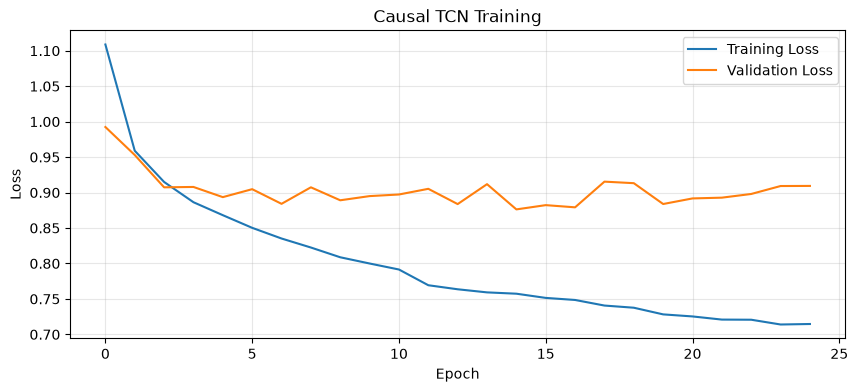

In [9]:

import numpy as np
import matplotlib.pyplot as plt

best_epoch = np.argmin(history.history["val_loss"])

print("Epochs trained:", len(history.history["loss"]))
print("Best epoch:", best_epoch + 1)

print("Best validation loss:",
      round(history.history["val_loss"][best_epoch], 4))

print("Validation accuracy at best epoch:",
      round(history.history["val_accuracy"][best_epoch], 4))

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Causal TCN Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Validation Accuracy: 61.91%
Macro F1: 0.6182

Classification Report:
              precision    recall  f1-score   support

        Wake     0.6774    0.5835    0.6270      2084
       Light     0.6430    0.6068    0.6244     11002
        Deep     0.5687    0.6328    0.5990      4463
         REM     0.6036    0.6425    0.6224      6302

    accuracy                         0.6191     23851
   macro avg     0.6232    0.6164    0.6182     23851
weighted avg     0.6217    0.6191    0.6194     23851



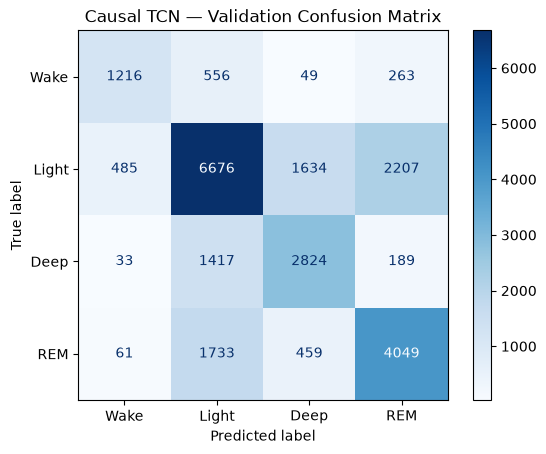

In [10]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Predict validation sequences
y_prob = tcn_model.predict(val_seq, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# True labels in generator order
y_true = y_val[val_seq.ends]

stage_names = ["Wake", "Light", "Deep", "REM"]

print("Validation Accuracy:",
      f"{accuracy_score(y_true, y_pred):.2%}")

print("Macro F1:",
      f"{f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=stage_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_names
).plot(cmap="Blues", values_format="d")

plt.title("Causal TCN — Validation Confusion Matrix")
plt.show()


In [11]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "person": val.iloc[val_seq.ends]["person"].to_numpy(),
    "position": val.iloc[val_seq.ends]["position"].to_numpy(),
    "actual": y_true,
    "predicted": y_pred
})

person_metrics = []

for person, group in results.groupby("person"):
    person_metrics.append({
        "Person": person,
        "Epochs": len(group),
        "Accuracy": accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Macro F1": f1_score(
            group["actual"],
            group["predicted"],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

person_metrics = pd.DataFrame(person_metrics)

print(
    person_metrics.sort_values("Macro F1").to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


   Person  Epochs  Accuracy  Macro F1
Bidslab38    1935    0.5411    0.4168
Bidslab31    3437    0.6200    0.5337
Bidslab64    3546    0.5970    0.5428
Bidslab11    4642    0.5974    0.5501
Bidslab49    1575    0.5498    0.5591
Bidslab09    3354    0.5954    0.6233
Bidslab16    5362    0.7150    0.7024


In [12]:

# Number of available epochs, including the current epoch
results["history_epochs"] = results["position"] + 1

# Group predictions by available history
results["context"] = pd.cut(
    results["history_epochs"],
    bins=[19, 39, 79, 119, np.inf],
    labels=[
        "10–19.5 min",
        "20–39.5 min",
        "40–59.5 min",
        "60+ min"
    ]
)

context_metrics = []

for context, group in results.groupby("context", observed=True):

    context_metrics.append({
        "Context": context,
        "Epochs": len(group),
        "Accuracy": accuracy_score(
            group["actual"],
            group["predicted"]
        ),
        "Macro F1": f1_score(
            group["actual"],
            group["predicted"],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

context_metrics = pd.DataFrame(context_metrics)

print(context_metrics.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))


    Context  Epochs  Accuracy  Macro F1
10–19.5 min    1137    0.6121    0.5667
20–39.5 min    1897    0.6837    0.6783
40–59.5 min    1778    0.6997    0.6746
    60+ min   19039    0.6055    0.5509


In [13]:

import numpy as np
import pandas as pd
import keras
from sklearn.metrics import accuracy_score, f1_score

# Select only epochs with a full 60 minutes of history
full_val_seq = CausalWindowSequence(
    X_val, y_val, val,
    window=120,
    batch_size=256,
    shuffle=False
)

full_val_seq.ends = np.where(
    val["position"].to_numpy() >= 119
)[0]

full_val_seq.order = np.arange(len(full_val_seq.ends))

print("Full-history validation epochs:", len(full_val_seq.ends))


# Keep only the most recent N epochs
class HistoryLimitSequence(keras.utils.Sequence):

    def __init__(self, base_sequence, keep):
        super().__init__()
        self.base = base_sequence
        self.keep = keep

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        X_batch, y_batch = self.base[index]

        # Hide older measurements
        X_batch[:, :-self.keep, :] = 0

        return X_batch, y_batch


y_true_full = y_val[full_val_seq.ends]

ablation_results = []

for keep in [20, 40, 80, 120]:

    limited_seq = HistoryLimitSequence(full_val_seq, keep)

    probabilities = tcn_model.predict(
        limited_seq, verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    ablation_results.append({
        "History (minutes)": keep / 2,
        "Accuracy": accuracy_score(
            y_true_full, predictions
        ),
        "Macro F1": f1_score(
            y_true_full,
            predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

ablation_df = pd.DataFrame(ablation_results)

print(ablation_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))


Full-history validation epochs: 19039
 History (minutes)  Accuracy  Macro F1
           10.0000    0.4963    0.4548
           20.0000    0.5500    0.5177
           40.0000    0.5712    0.5328
           60.0000    0.6055    0.5509


In [14]:

def add_elapsed_time(df):
    df = df.copy()

    # Find the first recorded epoch of each night
    first_epoch = df.groupby(
        ["person", "night"]
    )["epoch"].transform("min")

    # 120 epochs = 1 hour
    df["elapsed_hours"] = (
        df["epoch"] - first_epoch
    ) / 120.0

    return df


train = add_elapsed_time(train)
val = add_elapsed_time(val)

print("Training elapsed hours:")
print(train["elapsed_hours"].describe())

print("\nValidation elapsed hours:")
print(val["elapsed_hours"].describe())

print("\nMissing values:")
print("Training:", train["elapsed_hours"].isna().sum())
print("Validation:", val["elapsed_hours"].isna().sum())

print("\nSample:")
print(
    train[
        ["person", "night", "epoch", "elapsed_hours"]
    ].head(10)
)

Training elapsed hours:
count    139780.000000
mean          3.550501
std           2.155694
min           0.000000
25%           1.716667
50%           3.466667
75%           5.216667
max          10.008333
Name: elapsed_hours, dtype: float64

Validation elapsed hours:
count    25676.000000
mean         3.417953
std          2.117932
min          0.000000
25%          1.625000
50%          3.308333
75%          5.008333
max          9.533333
Name: elapsed_hours, dtype: float64

Missing values:
Training: 0
Validation: 0

Sample:
      person  night  epoch  elapsed_hours
0  Bidslab00      1      0       0.000000
1  Bidslab00      1      1       0.008333
2  Bidslab00      1      2       0.016667
3  Bidslab00      1      3       0.025000
4  Bidslab00      1      4       0.033333
5  Bidslab00      1      5       0.041667
6  Bidslab00      1      6       0.050000
7  Bidslab00      1      7       0.058333
8  Bidslab00      1      8       0.066667
9  Bidslab00      1      9       0.075000


In [15]:

from sklearn.preprocessing import StandardScaler
import numpy as np

# Original features + elapsed time
features_18 = features_17 + ["elapsed_hours"]

# Fit scaler on training data only
scaler_18 = StandardScaler()

X_train_18 = scaler_18.fit_transform(
    train[features_18]
).astype(np.float32)

X_val_18 = scaler_18.transform(
    val[features_18]
).astype(np.float32)

# Create 120-epoch sequences
train_seq_18 = CausalWindowSequence(
    X_train_18, y_train, train,
    window=120,
    batch_size=256,
    shuffle=True
)

val_seq_18 = CausalWindowSequence(
    X_val_18, y_val, val,
    window=120,
    batch_size=256,
    shuffle=False
)

# Verify
X_batch, y_batch = val_seq_18[0]

print("Features:", len(features_18))
print("Training shape:", X_train_18.shape)
print("Validation shape:", X_val_18.shape)

print("\nTraining sequences:", len(train_seq_18.ends))
print("Validation sequences:", len(val_seq_18.ends))
print("Batch shape:", X_batch.shape)

print("\nMissing/infinite values:")
print("Training:", (~np.isfinite(X_train_18)).sum())
print("Validation:", (~np.isfinite(X_val_18)).sum())

print("\nSame validation endpoints:",
      np.array_equal(val_seq.ends, val_seq_18.ends))


Features: 18
Training shape: (139780, 18)
Validation shape: (25676, 18)

Training sequences: 132616
Validation sequences: 23851
Batch shape: (256, 120, 18)

Missing/infinite values:
Training: 0
Validation: 0

Same validation endpoints: True


In [16]:

keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(120, 18))

x = inputs

for dilation in [1, 2, 4, 8, 16, 32]:
    x = residual_block(
        x,
        filters=32,
        dilation=dilation
    )

x = layers.Cropping1D(cropping=(119, 0))(x)
x = layers.Flatten()(x)

x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(4, activation="softmax")(x)

tcn_model_18 = keras.Model(
    inputs,
    outputs,
    name="TCN_Elapsed_Time"
)

tcn_model_18.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Total parameters:", tcn_model_18.count_params())


Total parameters: 19460


In [17]:

callbacks_18 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001
    ),

    keras.callbacks.ModelCheckpoint(
        "sleep_tcn_120x18_elapsed_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_18 = tcn_model_18.fit(
    train_seq_18,
    validation_data=val_seq_18,
    epochs=100,
    class_weight=soft_weights,
    callbacks=callbacks_18
)


Epoch 1/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.5259 - loss: 1.0238 - val_accuracy: 0.6247 - val_loss: 0.8767 - learning_rate: 0.0010
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6148 - loss: 0.8660 - val_accuracy: 0.6424 - val_loss: 0.8423 - learning_rate: 0.0010
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6425 - loss: 0.8240 - val_accuracy: 0.6537 - val_loss: 0.8197 - learning_rate: 0.0010
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6564 - loss: 0.7986 - val_accuracy: 0.6611 - val_loss: 0.8072 - learning_rate: 0.0010
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6647 - loss: 0.7782 - val_accuracy: 0.6536 - val_loss: 0.8183 - learning_rate: 0.0010
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6730 - loss: 0.7651 - val_accuracy: 0.6681 - val_loss: 0.8007 - learning_rate: 0.0010
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6794 - loss: 

Epochs trained: 17
Best epoch: 7
Best validation loss: 0.7824
Validation accuracy at best epoch: 0.6738


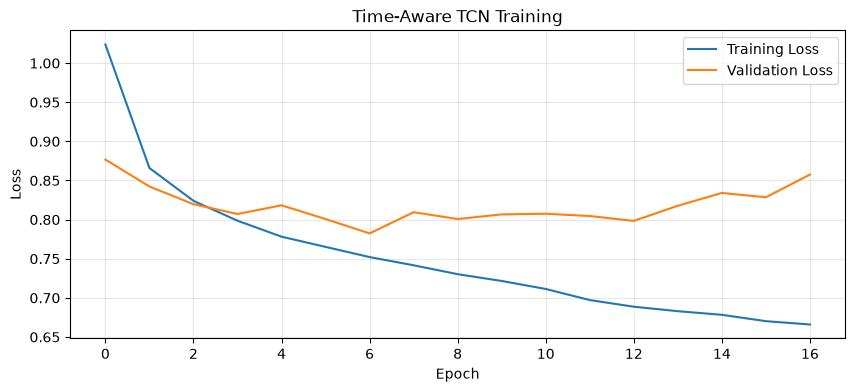

In [18]:

best_epoch_18 = np.argmin(history_18.history["val_loss"])

print("Epochs trained:", len(history_18.history["loss"]))
print("Best epoch:", best_epoch_18 + 1)

print("Best validation loss:",
      round(history_18.history["val_loss"][best_epoch_18], 4))

print("Validation accuracy at best epoch:",
      round(history_18.history["val_accuracy"][best_epoch_18], 4))

plt.figure(figsize=(10, 4))

plt.plot(history_18.history["loss"], label="Training Loss")
plt.plot(history_18.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Time-Aware TCN Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Validation Accuracy: 67.38%
Macro F1: 0.6640

Classification Report:
              precision    recall  f1-score   support

        Wake     0.6200    0.5988    0.6092      2084
       Light     0.7044    0.6553    0.6790     11002
        Deep     0.6422    0.8163    0.7188      4463
         REM     0.6696    0.6300    0.6492      6302

    accuracy                         0.6738     23851
   macro avg     0.6590    0.6751    0.6640     23851
weighted avg     0.6762    0.6738    0.6725     23851



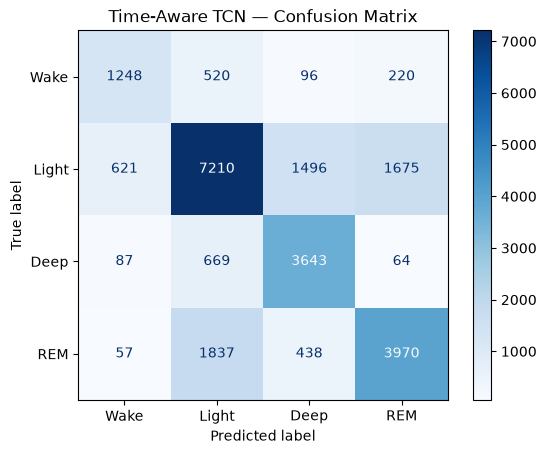

In [19]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

# Predictions
y_prob_18 = tcn_model_18.predict(val_seq_18)
y_pred_18 = np.argmax(y_prob_18, axis=1)

# Actual labels
y_true_18 = y_val[val_seq_18.ends]

stage_names = ["Wake", "Light", "Deep", "REM"]

print("Validation Accuracy:",
      f"{accuracy_score(y_true_18, y_pred_18):.2%}")

print("Macro F1:",
      f"{f1_score(y_true_18, y_pred_18, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_18,
    y_pred_18,
    labels=[0, 1, 2, 3],
    target_names=stage_names,
    digits=4
))

cm = confusion_matrix(
    y_true_18, y_pred_18,
    labels=[0, 1, 2, 3]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_names
).plot(cmap="Blues", values_format="d")

plt.title("Time-Aware TCN — Confusion Matrix")
plt.show()


In [20]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Confirm identical validation samples
assert np.array_equal(val_seq.ends, val_seq_18.ends)
assert np.array_equal(y_true, y_true_18)

persons = val.iloc[val_seq_18.ends]["person"].to_numpy()

comparison = []

for person in np.unique(persons):

    mask = persons == person

    actual = y_true_18[mask]
    old_pred = y_pred[mask]
    new_pred = y_pred_18[mask]

    old_f1 = f1_score(
        actual, old_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    new_f1 = f1_score(
        actual, new_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    comparison.append({
        "Person": person,
        "Epochs": len(actual),
        "Old Accuracy": accuracy_score(actual, old_pred),
        "New Accuracy": accuracy_score(actual, new_pred),
        "Old F1": old_f1,
        "New F1": new_f1,
        "F1 Change": new_f1 - old_f1
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nParticipants improved:",
      (comparison_df["F1 Change"] > 0).sum(),
      "out of", len(comparison_df))


   Person  Epochs  Old Accuracy  New Accuracy  Old F1  New F1  F1 Change
Bidslab09    3354        0.5954        0.6285  0.6233  0.6478     0.0245
Bidslab11    4642        0.5974        0.6364  0.5501  0.5817     0.0316
Bidslab16    5362        0.7150        0.7525  0.7024  0.7507     0.0483
Bidslab31    3437        0.6200        0.6826  0.5337  0.5892     0.0555
Bidslab38    1935        0.5411        0.6755  0.4168  0.5687     0.1519
Bidslab49    1575        0.5498        0.7003  0.5591  0.6933     0.1342
Bidslab64    3546        0.5970        0.6255  0.5428  0.5572     0.0144

Participants improved: 7 out of 7


In [21]:

import joblib
import keras
import numpy as np

# Save preprocessing configuration
joblib.dump(scaler_18, "scaler_tcn_18.pkl")
joblib.dump(features_18, "features_tcn_18.pkl")

# Load the best saved model
best_tcn = keras.models.load_model(
    "sleep_tcn_120x18_elapsed_best.keras"
)

# Verify saved model gives matching predictions
X_sample, _ = val_seq_18[0]

original_pred = tcn_model_18.predict(X_sample, verbose=0)
loaded_pred = best_tcn.predict(X_sample, verbose=0)

print("Model parameters:", best_tcn.count_params())

print("Saved model predictions match:",
      np.allclose(
          original_pred,
          loaded_pred,
          atol=1e-5
      ))

print("Saved features:", len(joblib.load("features_tcn_18.pkl")))

print("Saved scaler features:",
      joblib.load("scaler_tcn_18.pkl").n_features_in_)


Model parameters: 19460
Saved model predictions match: True
Saved features: 18
Saved scaler features: 18
